In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import pandas as pd
from scipy.stats import norm

In [13]:
# Чтение данных

# ==============================================================================

def read_data(file_path: str, max_rows: int | None = None) -> np.ndarray:
    return pd.read_csv(
        file_path, header=None, sep='|', decimal=',',
        nrows=max_rows, engine='c', usecols=[0]
    ).to_numpy(dtype=np.float64).ravel()

# ==============================================================================
def count_rows(file_path: str) -> int:
    if os.path.getsize(file_path) == 0:
        return 0
    
    n = 0
    with open(file_path, 'rb') as f:
        while chunk := f.read(1 << 20):
            n += chunk.count(b'\n')

    return n + (chunk[-1:] != b'\n')

# ==============================================================================

def read_data_writable(path: str, max_rows: int | None = None, n_chunk_rows: int = 10000) -> np.ndarray:
    if max_rows is None:
        max_rows = count_rows(path)
    arr = np.empty(max_rows, dtype=np.float64)

    idx = 0
    for df in pd.read_csv(path, chunksize=n_chunk_rows, nrows=max_rows, header=None, decimal=',', engine='c', usecols=[0]):
        chunk = df.iloc[:, 0].to_numpy()
        arr[idx:idx+len(chunk)] = chunk
        idx += len(chunk)
    
    return arr

In [14]:
from IPython import get_ipython

def set_widget_backend():
    plt.close('all')
    get_ipython().run_line_magic('matplotlib', 'widget')

def set_inline_backend():
    plt.close('all')
    get_ipython().run_line_magic('matplotlib', 'inline')

def set_scientific_yaxis(ax, scilimits=(0, 1)):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits(scilimits)
    ax.yaxis.set_major_formatter(fmt)

def set_scientific_xaxis(ax, scilimits=(0, 1)):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits(scilimits)
    ax.xaxis.set_major_formatter(fmt)

In [41]:
def plot_norm_hist(mu, sigma, n, bins, ax):
    x = np.linspace(bins[0], bins[-1], 1000)
    y = norm.pdf(x, mu, sigma)
    bin_width = bins[1] - bins[0]
    y *= n * bin_width
    ax.plot(x, y, linewidth=2, linestyle='--')

# Чтение данных

In [44]:
path = "C:\\Dev\\Code\\University\\4year-VKR\\results_1\\Ron_Roff.txt"
path2 = "C:\\Dev\\Code\\University\\4year-VKR\\results_1\\Vset_Vreset.txt"
path3 = "C:\\Dev\\Code\\University\\4year-VKR\\results_1\\shottky_params.txt"

R_on = []
R_off = []
V_set = []
V_reset = []
params = []

with open(path, encoding="utf-8") as f:
    for line in f.readlines():
        r_on, r_off = line.strip().split()
        R_on += [float(r_on)]
        R_off += [float(r_off)]

with open(path2, encoding="utf-8") as f:
    for line in f.readlines():
        v_set, v_reset = line.strip().split()
        V_set += [float(v_set)]
        V_reset += [float(v_reset)]

with open(path3, encoding="utf-8") as f:
    for line in f.readlines():
        phi, a_f, a_r, b_f, b_r = line.strip().split()
        params += [[float(phi), float(a_f), float(a_r), float(b_f), float(b_r)]]

In [45]:
R_on = np.array(R_on)
R_off = np.array(R_off)
V_set = np.array(V_set)
V_reset = np.array(V_reset)
params = np.array(params)

In [46]:
x = np.arange(len(R_on)) + 2

# Ron / Roff

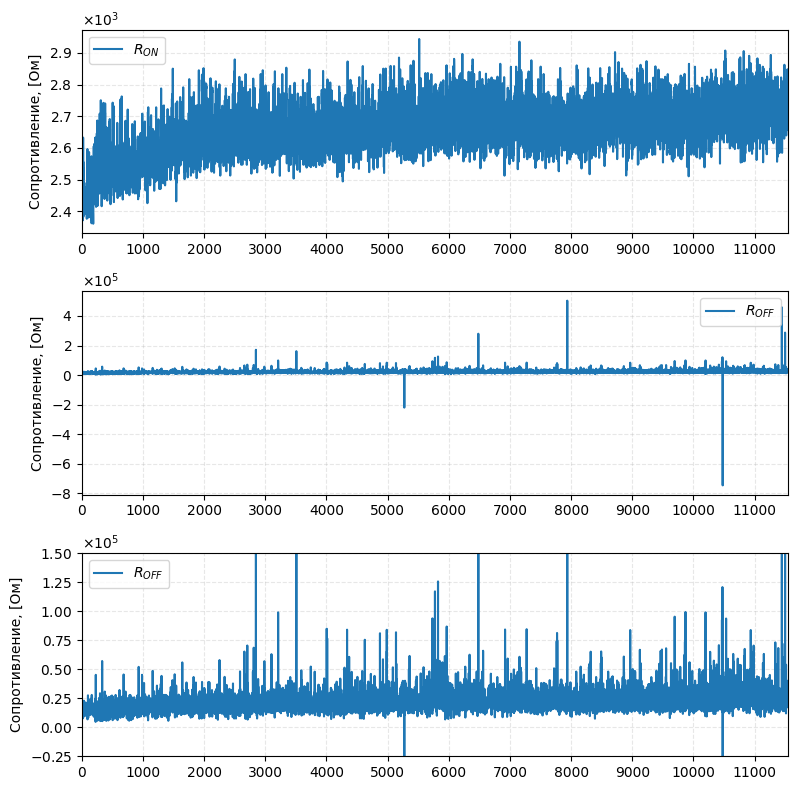

In [47]:
set_inline_backend()

fig, axes = plt.subplots(3, 1, figsize=(8, 8))
ax1, ax2, ax3 = axes

ax1.plot(x, R_on, label='$R_{ON}$')
ax2.plot(x, R_off, label='$R_{OFF}$')
ax3.plot(x, R_off, label='$R_{OFF}$')
ax3.set_ylim(-0.25e5, 1.5e5)

for ax in axes:
    set_scientific_yaxis(ax)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(x[0], x[-1])
    ax.set_xticks(np.arange(0, 12000, 1000))
    ax.set_ylabel('Сопротивление, [Ом]')
    ax.legend()

plt.tight_layout()
plt.show()

R_ON: mu=2660.5436928968948, sigma=81.1892352660928
R_OFF: mu=20098.511953637513, sigma=7533.913918993498


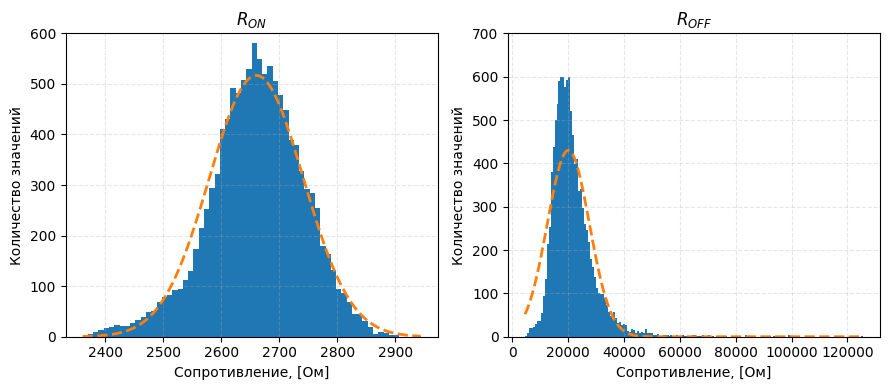

In [49]:
set_inline_backend()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ax1, ax2 = axes

q_low, q_high = np.percentile(R_off, [1, 99])

counts, bins, _ = ax1.hist(R_on, bins='auto')
mu, sigma = norm.fit(R_on)
plot_norm_hist(mu, sigma, len(R_on), bins, ax1)
print(f"R_ON: mu={mu}, sigma={sigma}")

data_off = R_off[(R_off >= 0) & (R_off <= 1.5e5)]
counts, bins, _ = ax2.hist(data_off, bins='auto')
mu, sigma = norm.fit(data_off)
mu -= 1.5e3
sigma -= 0.5e3
plot_norm_hist(mu, sigma, len(R_off), bins, ax2)
print(f"R_OFF: mu={mu}, sigma={sigma}")

ax1.set(xlabel='Сопротивление, [Ом]', ylabel='Количество значений', title='$R_{ON}$')
ax2.set(xlabel='Сопротивление, [Ом]', ylabel='Количество значений', title='$R_{OFF}$')
ax1.set_ylim(0, 600)
ax2.set_ylim(0, 700)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Vset / Vreset

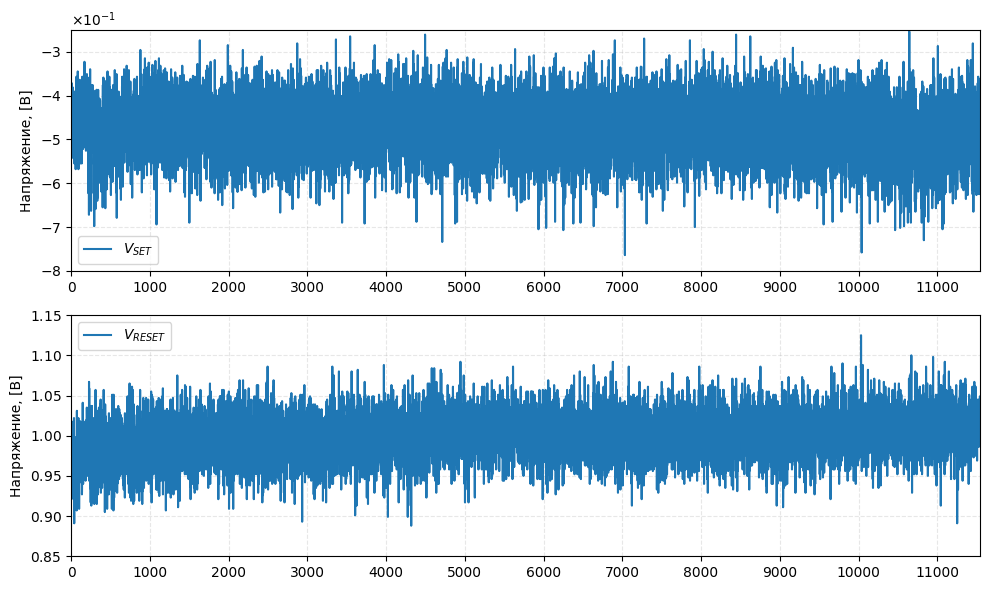

In [50]:
set_inline_backend()

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
ax1, ax2 = axes

ax1.plot(x, V_set, label='$V_{SET}$')
ax2.plot(x, V_reset, label='$V_{RESET}$')

ax1.set_ylim(-8e-1, -2.5e-1)
ax2.set_ylim(0.85, 1.15)

for ax in axes:
    set_scientific_yaxis(ax)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(x[0], x[-1])
    ax.set_xticks(np.arange(0, 12000, 1000))
    ax.set_ylabel('Напряжение, [В]')
    ax.legend()

ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

V_SET: mu=-0.47338546179171725, sigma=0.06782839411623653
V_RESET: mu=0.9997997747357478, sigma=0.02765621856253765


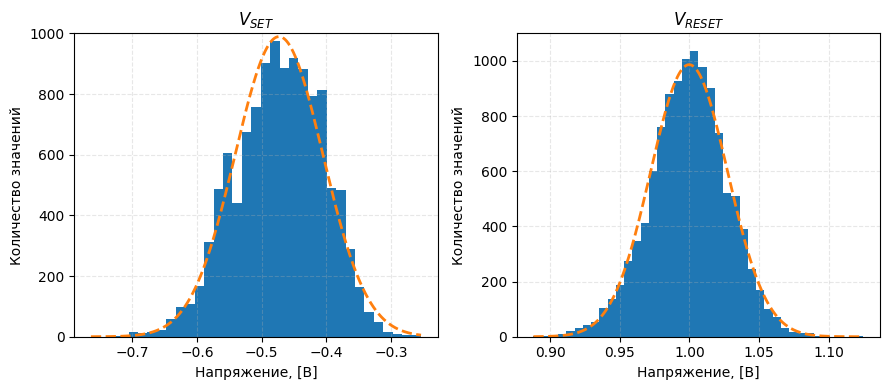

In [53]:
set_inline_backend()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ax1, ax2 = axes

q_low, q_high = np.percentile(R_off, [1, 99])

# bins1 = bins2 = 'auto'
bins1 = 35
bins2 = 40

counts, bins, _ = ax1.hist(V_set, bins=bins1)
mu, sigma = norm.fit(V_set)
plot_norm_hist(mu, sigma, len(V_set), bins, ax1)
print(f"V_SET: mu={mu}, sigma={sigma}")

counts, bins, _ = ax2.hist(V_reset, bins=bins2)
mu, sigma = norm.fit(V_reset)
plot_norm_hist(mu, sigma, len(V_reset), bins, ax2)
print(f"V_RESET: mu={mu}, sigma={sigma}")

ax1.set(xlabel='Напряжение, [В]', ylabel='Количество значений', title='$V_{SET}$')
ax2.set(xlabel='Напряжение, [В]', ylabel='Количество значений', title='$V_{RESET}$')

ax1.set_ylim(0, 1000)
ax2.set_ylim(0, 1100)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()
set_inline_backend()

# Shottky

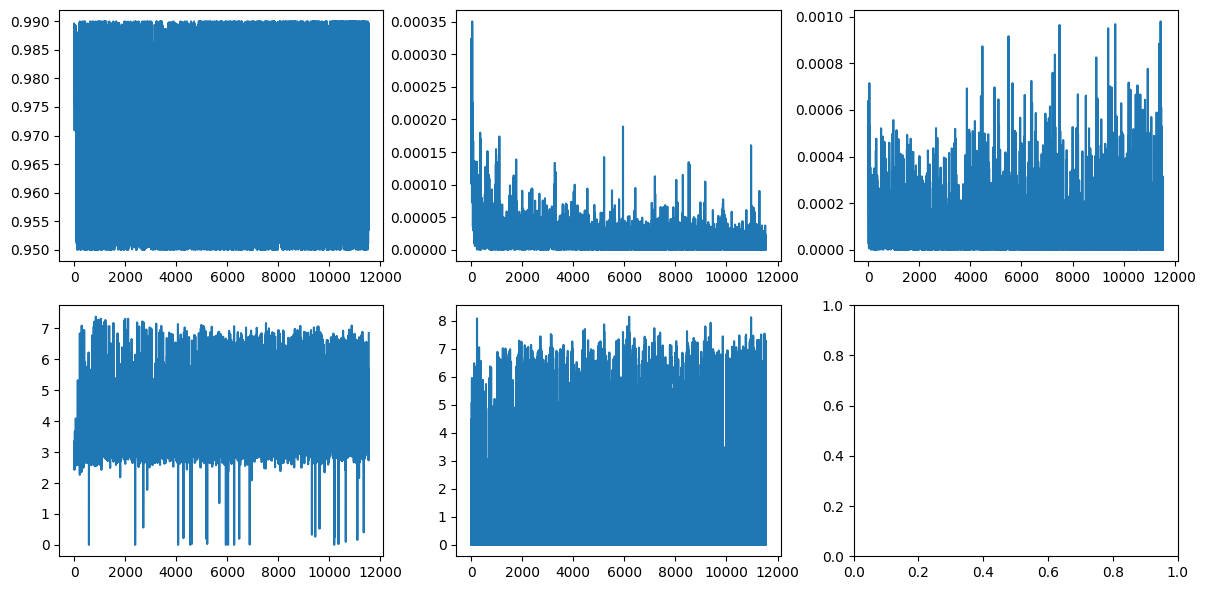

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()

for i in range(5):
    axes[i].plot(x, params[:, i])

plt.tight_layout()
plt.show()

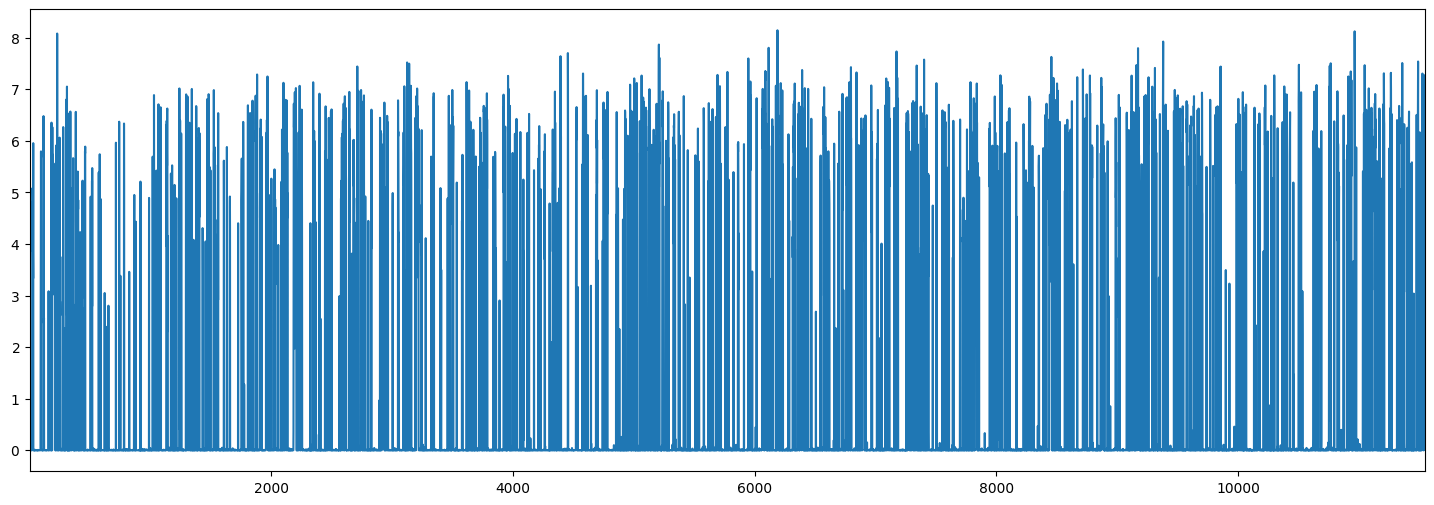

In [22]:
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(x, params[:, 4])
ax.set_xlim(x[0], x[-1])
set_scientific_yaxis(ax)

plt.show()

In [24]:
def export_data(params, path):
    params = np.asarray(params)

    with open(path, "w", encoding="utf-8") as f:
        for row in params:
            f.write(" ".join(f"{value:g}" for value in row[:5]) + "\n")

In [27]:
params_mean = params.mean(axis=0)

total_params_mean = [params_mean for i in range(len(params))]

export_data(total_params_mean, "shottky_mean.txt")

# Shottky deep anslysis

In [ ]:
import os
from scipy.signal import savgol_filter
import pandas as pd

In [34]:
def extract_schottky_current(V, a_f, a_r, b_f, b_r):
    return a_f * np.exp(b_f * V) - a_r * np.exp(-b_r * V)

def extract_memristive_current(I, phi, I_s):
    return (I - (1 - phi) * I_s) / phi

def calculate_G(V, I):
    G = np.empty_like(V)
    np.divide(I, V, out=G, where=(V != 0))
    G[V == 0] = np.inf
    return G

def get_num_periods(zero_indices, segments_per_period=2):
    if len(zero_indices) == 0:
        return 0
    if (len(zero_indices) + segments_per_period) % 2 == 0:
        return 1 + (len(zero_indices) - 1) // segments_per_period
    else:
        return (len(zero_indices) - 1) // segments_per_period
    
def find_zeros(signal: np.ndarray) -> np.ndarray:
    signal = np.asarray(signal)

    if signal.ndim != 1:
        raise ValueError("signal must be 1-dimensional")

    if signal.size < 2:
        return np.array([], dtype=int)

    left = signal[:-1]
    right = signal[1:]

    crosses = (
        (left == 0)
        | (right == 0)
        | ((left < 0) & (right > 0))
        | ((left > 0) & (right < 0))
    )

    if not np.any(crosses):
        return np.array([], dtype=int)

    idxs = np.flatnonzero(crosses)

    chosen = np.where(
        np.abs(left[idxs]) <= np.abs(right[idxs]),
        idxs,
        idxs + 1,
    )

    mask = np.concatenate(([True], chosen[1:] != chosen[:-1]))

    return chosen[mask].astype(int)

# ==============================================================================

def _filter_zero_candidates(
    zero_idxs: np.ndarray,
    min_distance: int,
) -> np.ndarray:
    zero_idxs = np.asarray(zero_idxs, dtype=int)

    if min_distance < 1:
        raise ValueError("min_distance must be positive")

    if zero_idxs.size == 0:
        return np.array([], dtype=int)

    groups = np.split(
        zero_idxs,
        np.flatnonzero(np.diff(zero_idxs) >= min_distance) + 1,
    )

    result = [
        group[(group.size - 1) // 2]
        for group in groups
    ]

    return np.array(result, dtype=int)

def find_stable_zeros(
    signal: np.ndarray,
    *,
    min_distance: int,
) -> np.ndarray:
    zero_idxs = find_zeros(signal)

    return _filter_zero_candidates(
        zero_idxs,
        min_distance=min_distance,
    )

def get_period_indices(n_signal_points: int, i: int, zero_indices: np.ndarray, segments_per_period: int = 2, period_start_segment_idx: int = 0):
    if (i < 0) or (segments_per_period < 1) or (period_start_segment_idx < 0):
        return (-1, -1)
    if len(zero_indices) == 0:
        return (0, n_signal_points)
    
    # normalize
    period_start_segment_idx %= segments_per_period

    if period_start_segment_idx >= len(zero_indices):
        return (0, n_signal_points) if i == 0 else (-1, -1)

    incomplete_on_start = 1 if zero_indices[0 + period_start_segment_idx] != 0 else 0
    p_start, p_end = i * segments_per_period, (i + 1) * segments_per_period

    p_start += period_start_segment_idx
    p_end += period_start_segment_idx
    
    start_zero_idx = p_start - incomplete_on_start * segments_per_period
    end_zero_idx = p_end - incomplete_on_start * segments_per_period

    if start_zero_idx >= len(zero_indices):
        return (-1, -1)

    start   = (zero_indices[start_zero_idx]) if (start_zero_idx >= 0) else (0)
    end     = (zero_indices[end_zero_idx]) if (end_zero_idx < len(zero_indices)) else (n_signal_points)
        
    return start, end

def detect_breakpoint_fast(
    y: np.ndarray,
    min_seg_len: int = 3,
    weights=(0.5, 0.5),
    x: np.ndarray = None
):
    n_points = len(y)
    
    # Если x не задан — используем равномерную сетку
    if x is None:
        x = np.arange(n_points)
    
    # Кумулятивные суммы для O(1) вычисления статистик сегментов
    cum_y = np.concatenate(([0], np.cumsum(y)))
    cum_y2 = np.concatenate(([0], np.cumsum(y**2)))
    cum_x = np.concatenate(([0], np.cumsum(x)))
    cum_x2 = np.concatenate(([0], np.cumsum(x**2)))
    cum_xy = np.concatenate(([0], np.cumsum(x * y)))

    # Закрытая формула RSS для линейной регрессии
    def _calc_rss(n, Sx, Sxx, Sy, Syy, Sxy):
        denom = n * Sxx - Sx**2
        if denom == 0: 
            return np.inf
        m = (n * Sxy - Sx * Sy) / denom
        c = (Sy - m * Sx) / n
        return max(0.0, Syy - 2*m*Sxy - 2*c*Sy + m**2*Sxx + 2*m*c*Sx + n*c**2)

    def _calc_total_rss(k):
        # Сегмент 1: [0, k)
        n1 = k
        Sx1 = cum_x[k] - cum_x[0]
        Sxx1 = cum_x2[k] - cum_x2[0]
        Sy1 = cum_y[k] - cum_y[0]
        Syy1 = cum_y2[k] - cum_y2[0]
        Sxy1 = cum_xy[k] - cum_xy[0]
        rss1 = _calc_rss(n1, Sx1, Sxx1, Sy1, Syy1, Sxy1)
        
        # Сегмент 2: [k, n_points)
        n2 = n_points - k
        Sx2 = cum_x[-1] - cum_x[k]
        Sxx2 = cum_x2[-1] - cum_x2[k]
        Sy2 = cum_y[-1] - cum_y[k]
        Syy2 = cum_y2[-1] - cum_y2[k]
        Sxy2 = cum_xy[-1] - cum_xy[k]
        rss2 = _calc_rss(n2, Sx2, Sxx2, Sy2, Syy2, Sxy2)
        
        return weights[0] * rss1 + weights[1] * rss2

    def _calc_grad(k, rss):
        if k + 1 >= n_points - min_seg_len:
            return 0
        rss2 = _calc_total_rss(k + 1)
        return rss2 - rss

    valid_range = range(min_seg_len, n_points - min_seg_len + 1)
    if len(valid_range) < 2:
        return min_seg_len, np.inf

    # Бинарный поиск точки излома
    k = -1
    k_prev = -3
    left = valid_range[0]
    right = valid_range[-1]

    while np.abs(k - k_prev) > 1:
        k_prev = k
        k = (left + right) // 2
        rss = _calc_total_rss(k)
        grad = _calc_grad(k, rss)

        if grad < 0:
            left = k
        else:
            right = k

    best_k = k
    best_rss = _calc_total_rss(best_k)
    return best_k, best_rss

def get_on_index(V_max_idx, V_min_idx, starts_with_hrs=True):
    return (min(V_max_idx, V_min_idx)) if (starts_with_hrs) else (max(V_max_idx, V_min_idx))

def get_off_index(V_max_idx, V_min_idx, starts_with_hrs=True):
    return (max(V_max_idx, V_min_idx)) if (starts_with_hrs) else (min(V_max_idx, V_min_idx))

# ==================================================================================================

def detect_set(V, I, on_index, V0_index, k=1.0, starts_with_hrs=True):
    if starts_with_hrs:
        index, _ = detect_breakpoint_fast(I[0 : on_index + 1], weights=(k, 1.0), x=V[0 : on_index + 1])
        return index
    else:
        index, _ = detect_breakpoint_fast(I[V0_index : on_index + 1], weights=(k, 1.0), x=V[V0_index : on_index + 1])
        return V0_index + index

# ==============================================================================

def detect_reset(V, I, off_index, V0_index, k=1.0, starts_with_hrs=True):
    if starts_with_hrs:
        index, _ = detect_breakpoint_fast(I[V0_index : off_index + 1], weights=(k, 1.0), x=V[V0_index : off_index + 1])
        return V0_index + index
    else:
        index, _ = detect_breakpoint_fast(I[0 : off_index + 1], weights=(k, 1.0), x=V[0 : off_index + 1])
        return index
    
def filter_current(I, period_samples, high_smooth=True, mode='wrap'):
    high_smooth_window = int(round(period_samples * (101 / 5200)))
    soft_smooth_window = int(round(period_samples * (31 / 5200)))

    high_smooth_window += int(high_smooth_window % 2 == 0)
    soft_smooth_window += int(soft_smooth_window % 2 == 0)

    if high_smooth:
        window = min(len(I) - int(len(I) % 2 == 0), high_smooth_window)
        return savgol_filter(I, window_length=window, polyorder=3, mode=mode)
    else:
        window = min(len(I) - int(len(I) % 2 == 0), soft_smooth_window)
        return savgol_filter(I, window_length=window, polyorder=3, mode=mode)

In [37]:
ROOT_DIR = "C:/Dev/Data/University/VKR/Датасеты_мемристоров_ННГУ/Временные ряды для ЛЭТИ 2023_06_07"

PATH_TO_IN = os.path.join(ROOT_DIR, "Input Voltage Pila -1.1_1.5V_full.txt")
PATH_TO_OUT = os.path.join(ROOT_DIR, "Output Voltage Pila-1.1+1.5V_1e6_1e6_1kOhm_1.txt")

dt = 1e-6   # time step 
R = 1000    # resistance

max_rows = min(count_rows(PATH_TO_IN), count_rows(PATH_TO_OUT))

arr_v = read_data(PATH_TO_IN, max_rows=max_rows)
arr_i = read_data_writable(PATH_TO_OUT, max_rows=max_rows, n_chunk_rows=100_000)
arr_i /= R

print(f"Input length: {len(arr_v)}")
print(f"Output length: {len(arr_i)}")

Input length: 60026492
Output length: 60026492


In [38]:
arr_v_zeros = find_stable_zeros(arr_v, min_distance=(5200/6))

In [54]:
def calc_rss(x, y):  
    m, c = np.polyfit(x, y, 1)
    rss = np.sum((y - (m*x + c))**2)
    return rss

In [75]:
n_cycles = get_num_periods(arr_v_zeros)
period_samples = 5200

I_HRS_rss = []
I_m_HRS_rss = []
I_LRS_rss = []
I_m_LRS_rss = []

for i in range(1, n_cycles):
    start, end = get_period_indices(arr_v.size, i, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    phi, a_f, a_r, b_f, b_r = params[i - 1]

    V = arr_v[start : end]; I = arr_i[start : end]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)
    V0_idx = V_zeros[1]

    I_m_smoothed = filter_current(I_m, period_samples, high_smooth=True, mode='wrap')
    on_index = get_on_index(V_max_idx, V_min_idx, starts_with_hrs=False)
    off_index = get_off_index(V_max_idx, V_min_idx, starts_with_hrs=False)
    set_index = detect_set(V, I_m_smoothed, on_index, V0_idx, k=50, starts_with_hrs=False)
    reset_index = detect_reset(V, I_m_smoothed, off_index, V0_idx, k=5, starts_with_hrs=False)

    I_m_HRS = I_m[off_index : set_index]
    I_HRS = I[off_index : set_index]
    V_HRS = V[off_index : set_index]
    
    I_LRS = np.concatenate([I[on_index : ], I[ : reset_index]], axis=0)
    I_m_LRS = np.concatenate([I_m[on_index : ], I_m[ : reset_index]], axis=0)
    V_LRS = np.concatenate([V[on_index : ], V[ : reset_index]], axis=0)

    I_HRS_rss += [calc_rss(V_HRS, I_HRS)]
    I_m_HRS_rss += [calc_rss(V_HRS, I_m_HRS)]
    I_LRS_rss += [calc_rss(V_LRS, I_LRS)]
    I_m_LRS_rss += [calc_rss(V_LRS, I_m_LRS)]

    # plt.plot(V, I)
    # plt.plot(V, I_m)
    # plt.plot(V_HRS, I_m_HRS)
    # plt.plot(V_LRS, I_m_LRS)
    # plt.show()
    # break


I_HRS_rss = np.array(I_HRS_rss)
I_m_HRS_rss = np.array(I_m_HRS_rss)
I_LRS_rss = np.array(I_LRS_rss)
I_m_LRS_rss = np.array(I_m_LRS_rss)

mean(I_HRS_rss) = 7.115323341777523e-07
mean(I_m_HRS_rss) = 8.628690338369747e-08
mean(I_LRS_rss) = 5.3363356264626805e-08
mean(I_m_LRS_rss) = 8.647593702497094e-08


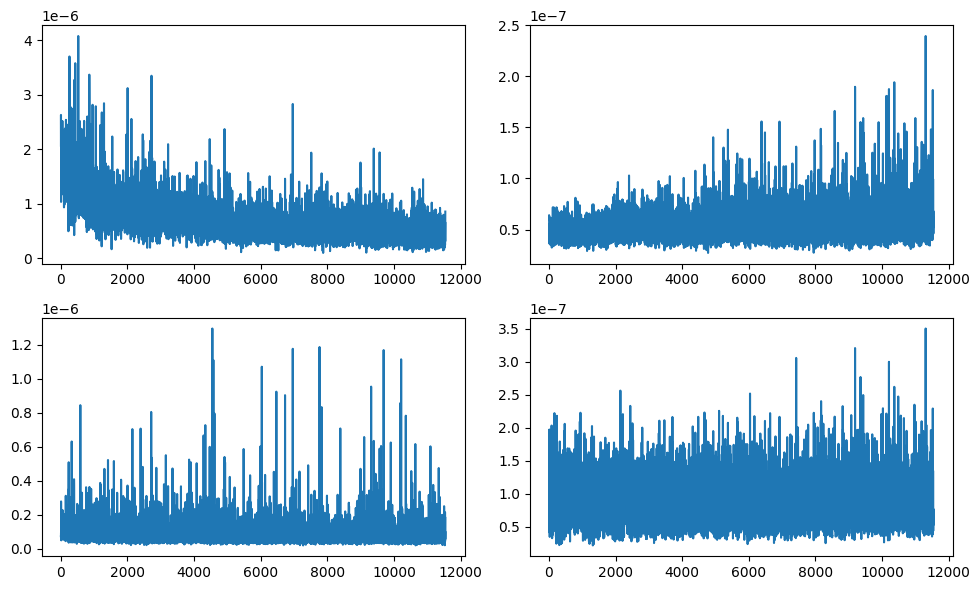

In [76]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
ax1, ax2, ax3, ax4 = axes.ravel()

ax1.plot(x, I_HRS_rss)
ax2.plot(x, I_LRS_rss)
ax3.plot(x, I_m_HRS_rss)
ax4.plot(x, I_m_LRS_rss)

print(f"mean(I_HRS_rss) = {np.mean(I_HRS_rss)}")
print(f"mean(I_m_HRS_rss) = {np.mean(I_m_HRS_rss)}")
print(f"mean(I_LRS_rss) = {np.mean(I_LRS_rss)}")
print(f"mean(I_m_LRS_rss) = {np.mean(I_m_LRS_rss)}")

plt.tight_layout()
plt.show()